# 🏷️ Name That LLM — Stylistic Fingerprinting

### Idea + Thought Process
1. Check how many prompts each 18 models (6 families) have
2. Length of prompt for each model (box plot) — length vs model
3. Words each model likes to use
4. Punctuation (`-` `,` `:` `;`) usage by model
5. Patterns (sentence structure, vocabulary richness)
6. Family characteristics → then model characteristics

Finally: build a classifier and produce `submission.parquet`

In [7]:
# ============================================================
# Cell 1 — Imports & Data Loading
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from collections import Counter

sns.set_theme(style='whitegrid', palette='tab20', font_scale=0.9)
plt.rcParams['figure.dpi'] = 120

# ---------- paths (toggle for Kaggle vs local) ----------
import os
if os.path.exists('/kaggle/input/competitions/name-that-llm/train.csv'):
    TRAIN_PATH = '/kaggle/input/competitions/name-that-llm/train.csv'
    TEST_PATH  = '/kaggle/input/competitions/name-that-llm/test.csv'
    SAMPLE_PATH = '/kaggle/input/competitions/name-that-llm/sample_submission.parquet'
else:
    TRAIN_PATH = '/Users/sahaj/Documents/promptly-named/dataset/train.csv'
    TEST_PATH  = '/Users/sahaj/Documents/promptly-named/dataset/test.csv'
    SAMPLE_PATH = '/Users/sahaj/Documents/promptly-named/dataset/sample_submission.parquet'

train = pd.read_csv(TRAIN_PATH)
test  = pd.read_csv(TEST_PATH)

print(f'Train shape: {train.shape}')
print(f'Test shape:  {test.shape}')
train.head()

Train shape: (2699, 4)
Test shape:  (3, 2)


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [8]:
# ============================================================
# Valid Labels & Provider Mapping
# ============================================================
VALID_LABELS = [
    'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra',
    'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash',
    'claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5',
    'qwen3.8-max',
    'glm-5.3', 'glm-5.3-flash',
    'kimi-k3',
]

MODEL_TO_FAMILY = {}
for m in VALID_LABELS:
    if m.startswith('gpt'):     MODEL_TO_FAMILY[m] = 'OpenAI'
    elif m.startswith('gemini'):MODEL_TO_FAMILY[m] = 'Google'
    elif m.startswith('claude'):MODEL_TO_FAMILY[m] = 'Anthropic'
    elif m.startswith('qwen'): MODEL_TO_FAMILY[m] = 'Qwen'
    elif m.startswith('glm'):  MODEL_TO_FAMILY[m] = 'ZAI'
    elif m.startswith('kimi'): MODEL_TO_FAMILY[m] = 'Moonshot AI'

train['family'] = train['model'].map(MODEL_TO_FAMILY)
print(f'Unique models: {train["model"].nunique()}')
print(f'Unique families: {train["family"].nunique()}')
assert set(train['model'].unique()) == set(VALID_LABELS), 'Label mismatch!'

Unique models: 18
Unique families: 6


---
## 1️⃣ How many prompts each model has

/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/280283576.py:14: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  plt.tight_layout()
/Users/sahaj/Documents/promptly-named/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


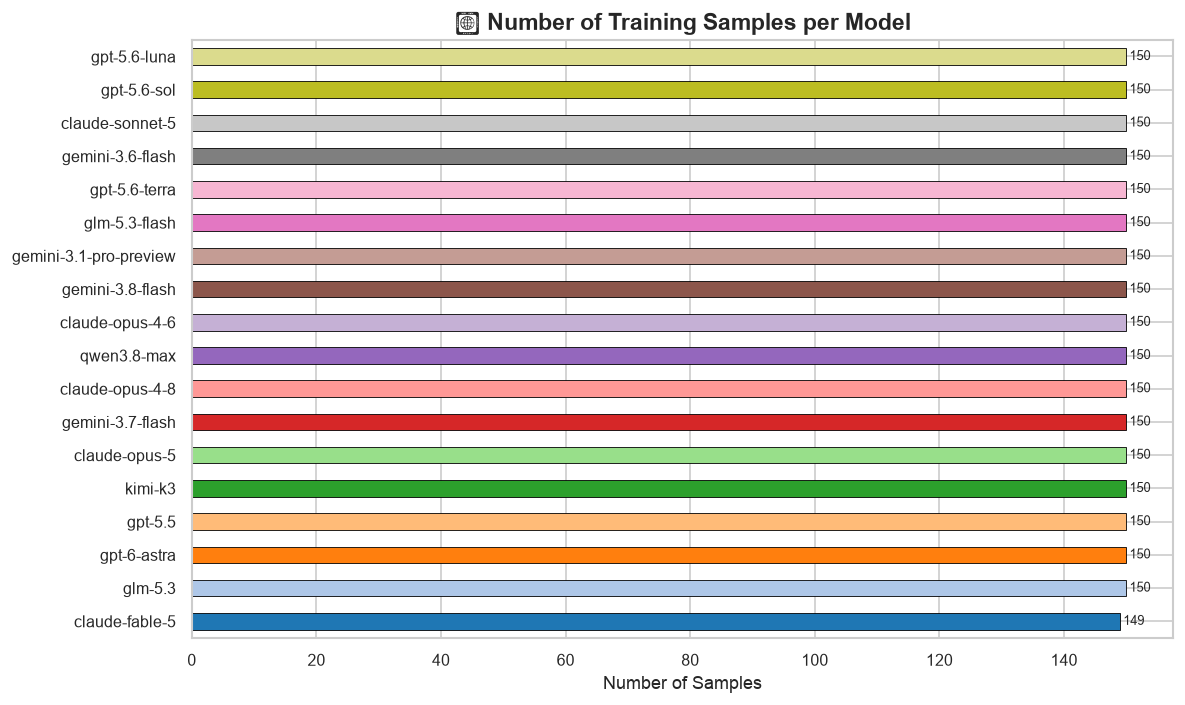


Total training samples: 2699
Unique prompts: 150

Samples per model:
model
qwen3.8-max               150
claude-sonnet-5           150
gemini-3.6-flash          150
gpt-5.6-terra             150
glm-5.3-flash             150
gemini-3.1-pro-preview    150
gemini-3.8-flash          150
claude-opus-4-6           150
gpt-5.6-luna              150
claude-opus-4-8           150
gemini-3.7-flash          150
claude-opus-5             150
kimi-k3                   150
gpt-5.5                   150
gpt-6-astra               150
glm-5.3                   150
gpt-5.6-sol               150
claude-fable-5            149


In [9]:
# ============================================================
# 1. Prompt count per model
# ============================================================
model_counts = train['model'].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
colors = [sns.color_palette('tab20')[i] for i in range(len(model_counts))]
model_counts.plot.barh(ax=ax, color=colors, edgecolor='black', linewidth=0.5)
ax.set_xlabel('Number of Samples')
ax.set_ylabel('')
ax.set_title('📊 Number of Training Samples per Model', fontsize=14, fontweight='bold')
for i, (val, name) in enumerate(zip(model_counts.values, model_counts.index)):
    ax.text(val + 0.5, i, str(val), va='center', fontsize=8)
plt.tight_layout()
plt.show()

print(f'\nTotal training samples: {len(train)}')
print(f'Unique prompts: {train["prompt_id"].nunique()}')
print(f'\nSamples per model:')
print(train['model'].value_counts().to_string())

---
## 2️⃣ Text Length Distribution per Model (Box Plot)

/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/1126756451.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, y='model', x='text_len', order=order, ax=axes[0],
/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/1126756451.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, y='model', x='word_count', order=order_w, ax=axes[1],
/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/1126756451.py:27: UserWarning: Glyph 128207 (\N{STRAIGHT RULER}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/1126756451.py:27: UserWarning: Glyph 128221 (\N{MEMO}) missing from 

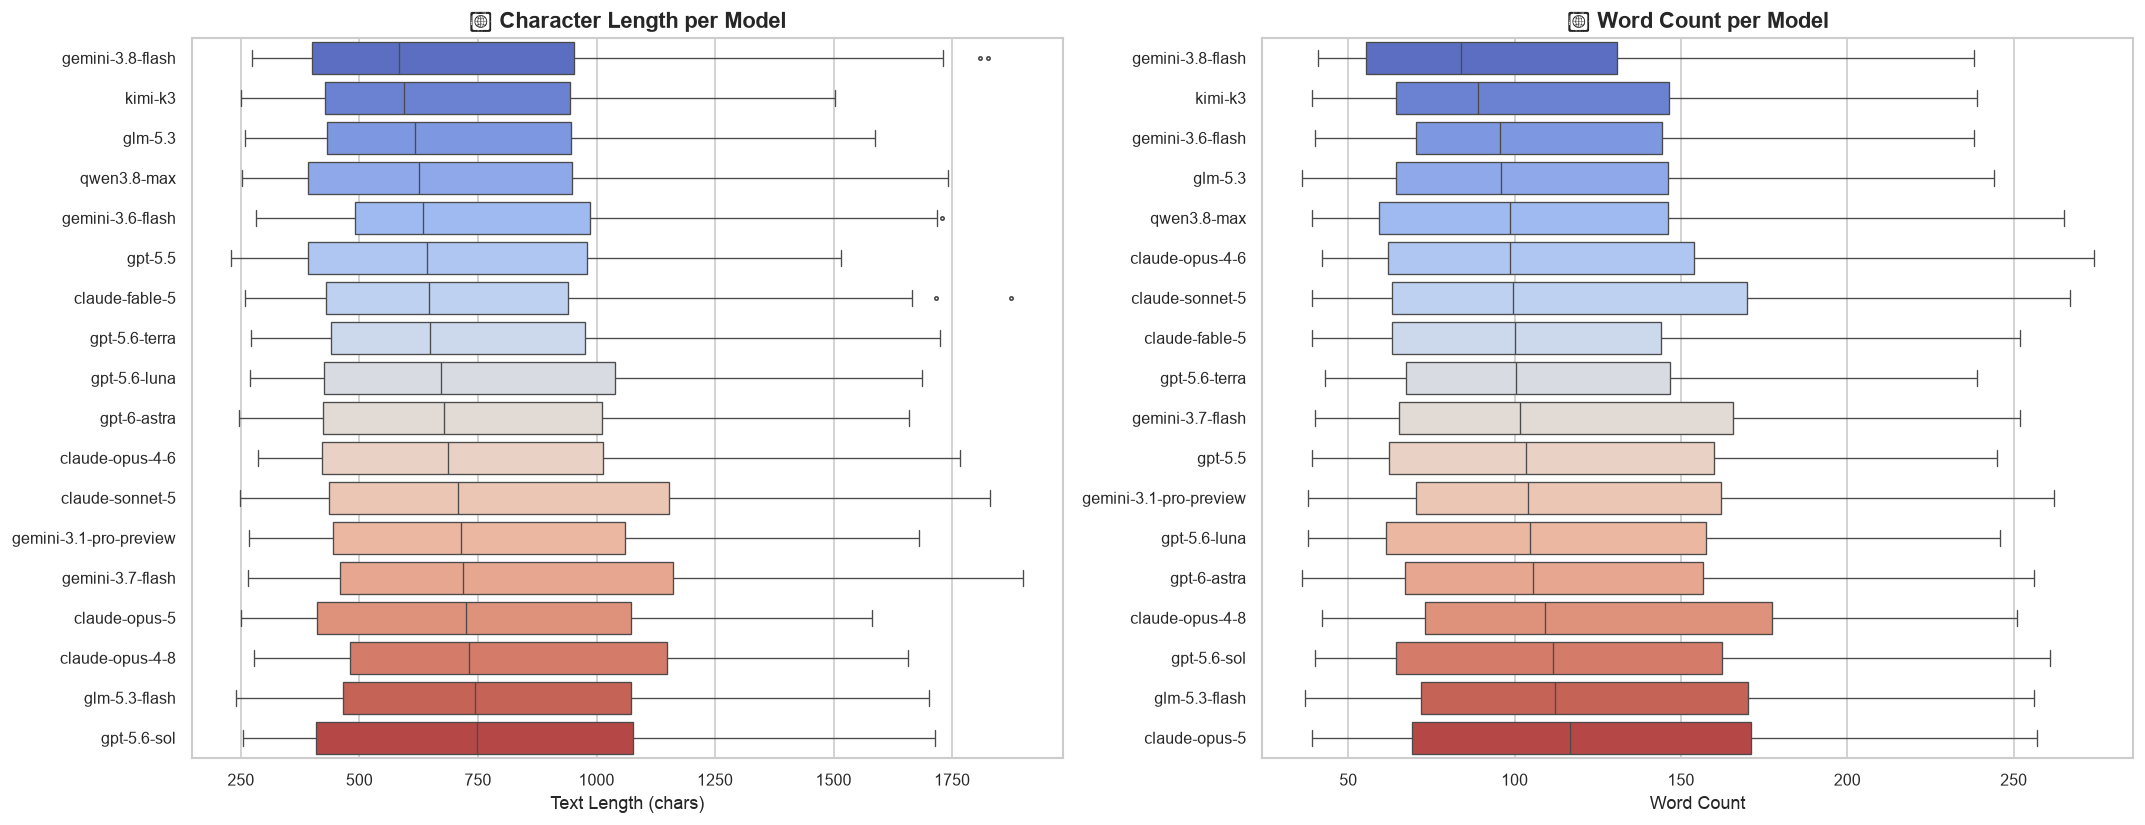

In [10]:
# ============================================================
# 2. Length of text per model — box plot
# ============================================================
train['text_len'] = train['text'].str.len()
train['word_count'] = train['text'].str.split().str.len()

# order models by median text length
order = train.groupby('model')['text_len'].median().sort_values().index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# character length
sns.boxplot(data=train, y='model', x='text_len', order=order, ax=axes[0],
            palette='coolwarm', fliersize=2, linewidth=0.8)
axes[0].set_title('📏 Character Length per Model', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Text Length (chars)')
axes[0].set_ylabel('')

# word count
order_w = train.groupby('model')['word_count'].median().sort_values().index.tolist()
sns.boxplot(data=train, y='model', x='word_count', order=order_w, ax=axes[1],
            palette='coolwarm', fliersize=2, linewidth=0.8)
axes[1].set_title('📝 Word Count per Model', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

---
## 3️⃣ Words Each Model Likes to Use

In [11]:
# ============================================================
# 3. Distinctive words per model (TF-IDF based)
# ============================================================
from sklearn.feature_extraction.text import TfidfVectorizer

# aggregate all text per model into one big document
model_docs = train.groupby('model')['text'].apply(' '.join).reset_index()

tfidf = TfidfVectorizer(max_features=5000, stop_words='english',
                         ngram_range=(1, 1), min_df=1)
tfidf_matrix = tfidf.fit_transform(model_docs['text'])
feature_names = np.array(tfidf.get_feature_names_out())

print('Top 15 distinctive words per model:\n')
top_words = {}
for i, model_name in enumerate(model_docs['model']):
    row = tfidf_matrix[i].toarray().flatten()
    top_idx = row.argsort()[-15:][::-1]
    words = feature_names[top_idx]
    top_words[model_name] = list(words)
    print(f'  {model_name:30s} → {", ".join(words[:10])}')

print()

Top 15 distinctive words per model:

  claude-fable-5                 → like, light, water, time, years, life, world, pa, single, earth
  claude-opus-4-6                → like, light, single, years, human, world, earth, ancient, entire, water
  claude-opus-4-8                → like, single, light, beneath, world, dark, quietly, vast, time, life
  claude-opus-5                  → like, light, single, years, dark, body, world, water, room, arrives
  claude-sonnet-5                → like, light, beneath, single, universe, water, vast, life, world, self
  gemini-3.1-pro-preview         → human, world, universe, profound, dark, cosmic, single, absolute, entirely, space
  gemini-3.6-flash               → human, silent, ancient, dark, single, light, cosmic, like, world, void
  gemini-3.7-flash               → human, beneath, merely, silent, like, ancient, profound, cosmic, light, dark
  gemini-3.8-flash               → human, beneath, silent, dark, ancient, like, life, merely, architecture, t

/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/2150251850.py:20: UserWarning: Glyph 128292 (\N{INPUT SYMBOL FOR LATIN LETTERS}) missing from font(s) Arial.
  plt.tight_layout()
/Users/sahaj/Documents/promptly-named/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128292 (\N{INPUT SYMBOL FOR LATIN LETTERS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


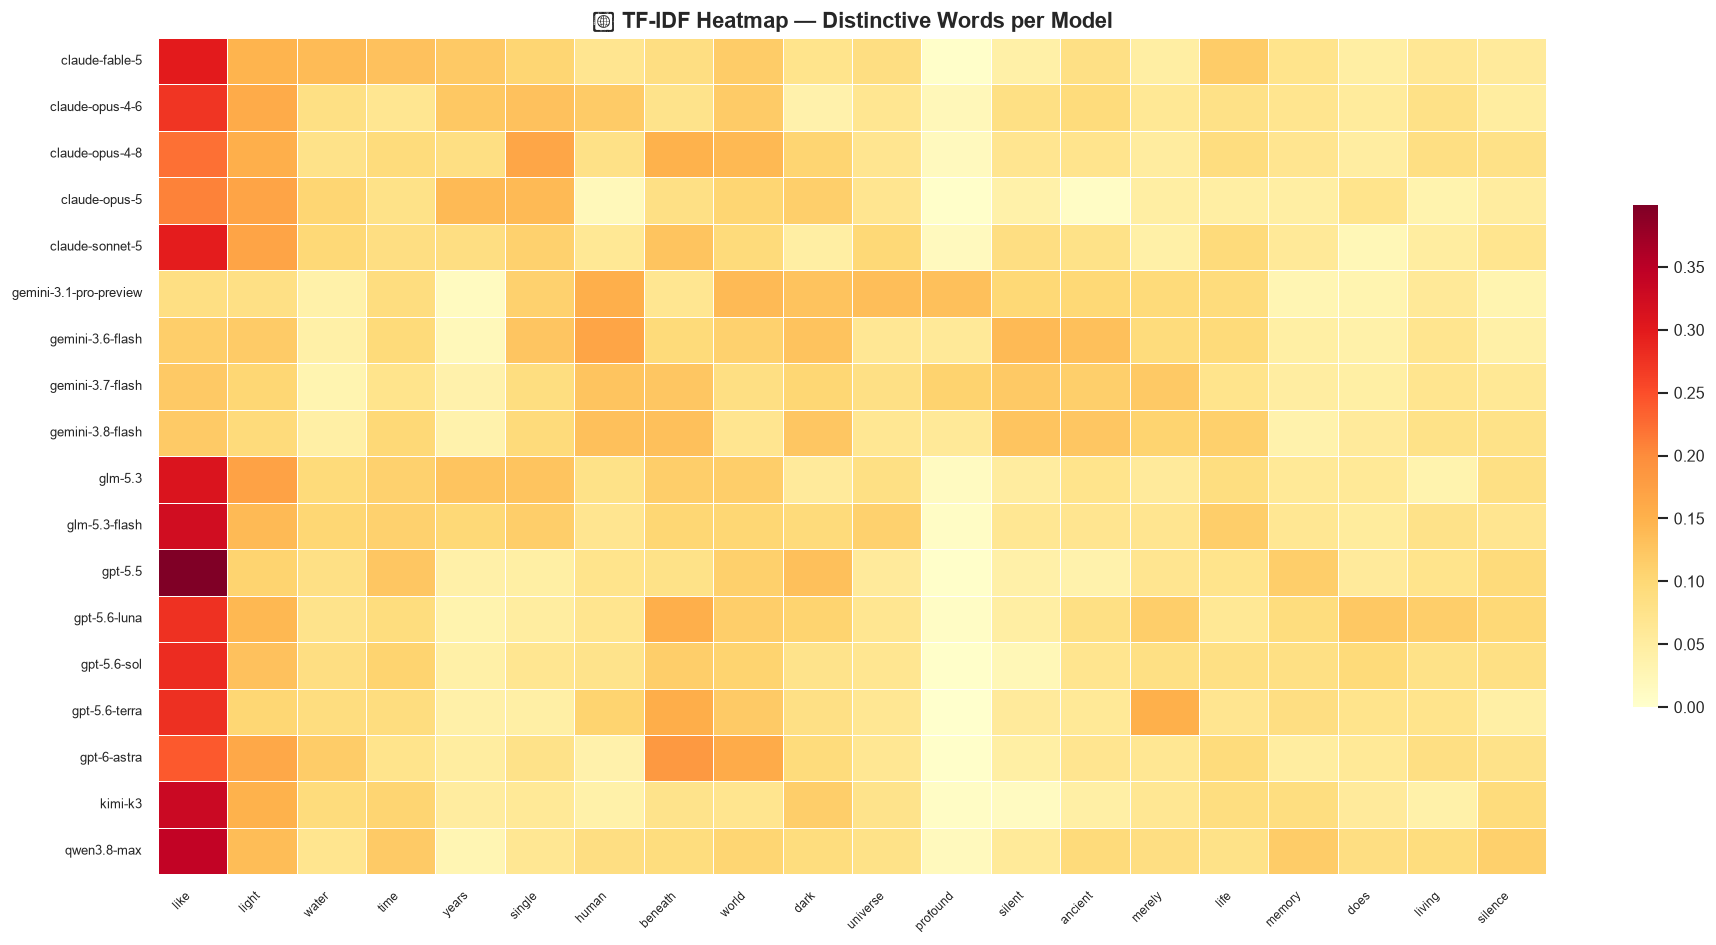

In [12]:
# visual: heatmap of top words across models
# pick top 5 words per model → union
top_union = []
for m, ws in top_words.items():
    top_union.extend(ws[:5])
top_union = list(dict.fromkeys(top_union))  # deduplicate, preserve order

# filter to these words
word_idx = [list(feature_names).index(w) for w in top_union if w in feature_names]
sub_matrix = tfidf_matrix[:, word_idx].toarray()
df_heat = pd.DataFrame(sub_matrix, index=model_docs['model'],
                        columns=[feature_names[i] for i in word_idx])

fig, ax = plt.subplots(figsize=(16, 8))
sns.heatmap(df_heat, cmap='YlOrRd', linewidths=0.3, ax=ax, cbar_kws={'shrink': 0.6})
ax.set_title('🔤 TF-IDF Heatmap — Distinctive Words per Model', fontsize=13, fontweight='bold')
ax.set_ylabel('')
plt.xticks(rotation=45, ha='right', fontsize=7)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

---
## 4️⃣ Punctuation Usage by Model

In [13]:
# ============================================================
# 4. Punctuation usage analysis
# ============================================================
punct_chars = ['-', ',', ':', ';', '!', '?', '(', ')', '"', "'"]

for p in punct_chars:
    col_name = f'punct_{p}'
    train[col_name] = train['text'].apply(lambda x: x.count(p))

# normalize by text length (per 1000 chars)
for p in punct_chars:
    train[f'punct_{p}_norm'] = train[f'punct_{p}'] / train['text_len'] * 1000

# summary table
punct_cols_norm = [f'punct_{p}_norm' for p in punct_chars]
punct_summary = train.groupby('model')[punct_cols_norm].mean()
punct_summary.columns = punct_chars
print('Average punctuation per 1000 chars by model:\n')
print(punct_summary.round(2).to_string())

Average punctuation per 1000 chars by model:

                           -      ,     :     ;     !     ?     (     )     "     '
model                                                                              
claude-fable-5          0.90  14.19  1.04  0.55  0.00  0.06  0.06  0.06  0.22  1.55
claude-opus-4-6         1.11  11.58  0.56  0.18  0.00  0.04  0.00  0.00  0.26  1.46
claude-opus-4-8         0.87  14.57  0.76  0.30  0.00  0.06  0.02  0.02  0.20  1.36
claude-opus-5           0.95  13.55  1.29  0.95  0.02  0.08  0.02  0.02  0.33  1.62
claude-sonnet-5         1.26  14.37  0.87  0.34  0.01  0.02  0.01  0.01  0.35  2.21
gemini-3.1-pro-preview  0.18  11.47  0.25  0.24  0.01  0.09  0.00  0.00  0.04  0.18
gemini-3.6-flash        0.20  12.31  0.25  0.29  0.00  0.07  0.01  0.01  0.09  0.37
gemini-3.7-flash        0.32  11.73  0.25  0.29  0.00  0.04  0.02  0.02  0.00  0.24
gemini-3.8-flash        0.23  12.22  0.27  0.41  0.00  0.04  0.00  0.00  0.01  0.21
glm-5.3                 0.98  

/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/687834404.py:7: UserWarning: Glyph 9999 (\N{PENCIL}) missing from font(s) Arial.
  plt.tight_layout()
/Users/sahaj/Documents/promptly-named/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9999 (\N{PENCIL}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


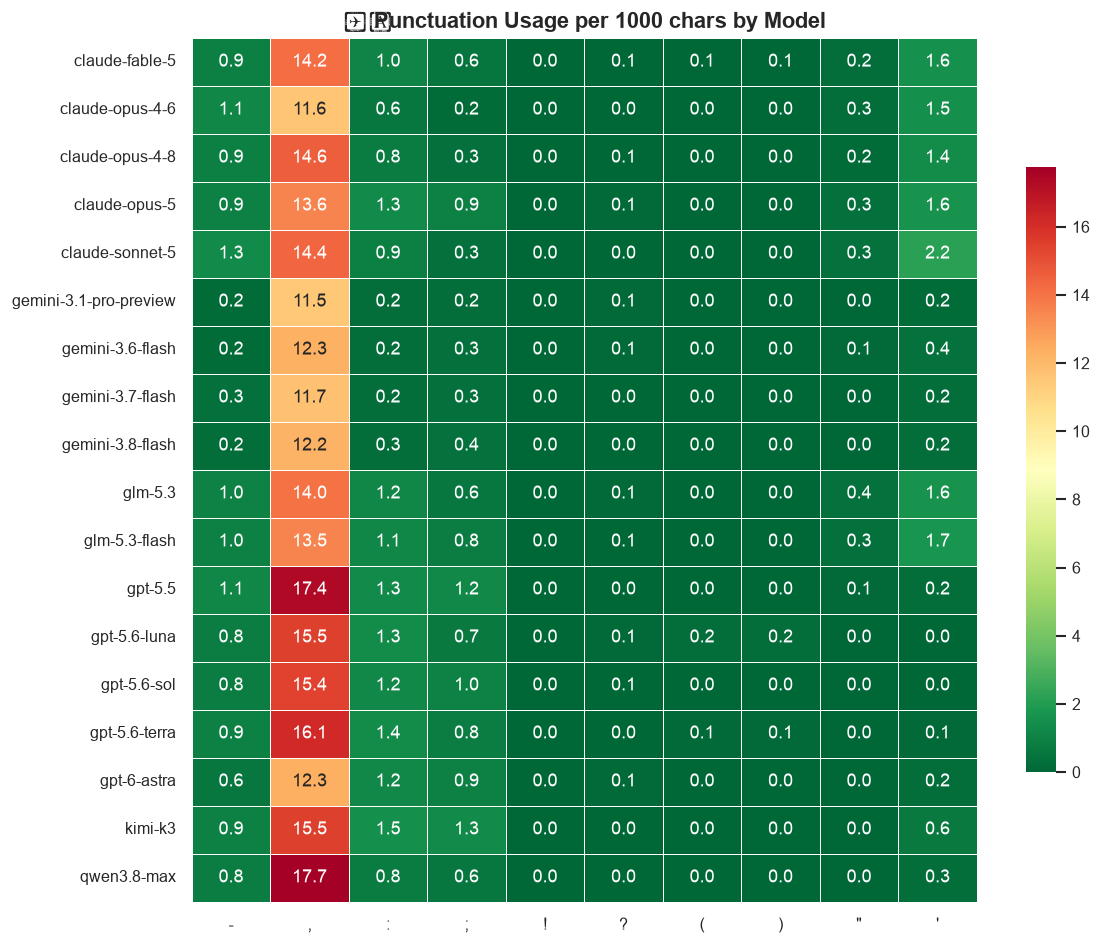

In [14]:
# punctuation heatmap
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(punct_summary.round(2), annot=True, fmt='.1f', cmap='RdYlGn_r',
            linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.7})
ax.set_title('✏️ Punctuation Usage per 1000 chars by Model', fontsize=13, fontweight='bold')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/2340404285.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, y='model', x=f'punct_{p}_norm',
/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/2340404285.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, y='model', x=f'punct_{p}_norm',
/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/2340404285.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, y='model', x=f'punct_{p}_norm',
/var/folders/3z/l6z34vg53pb1zqh

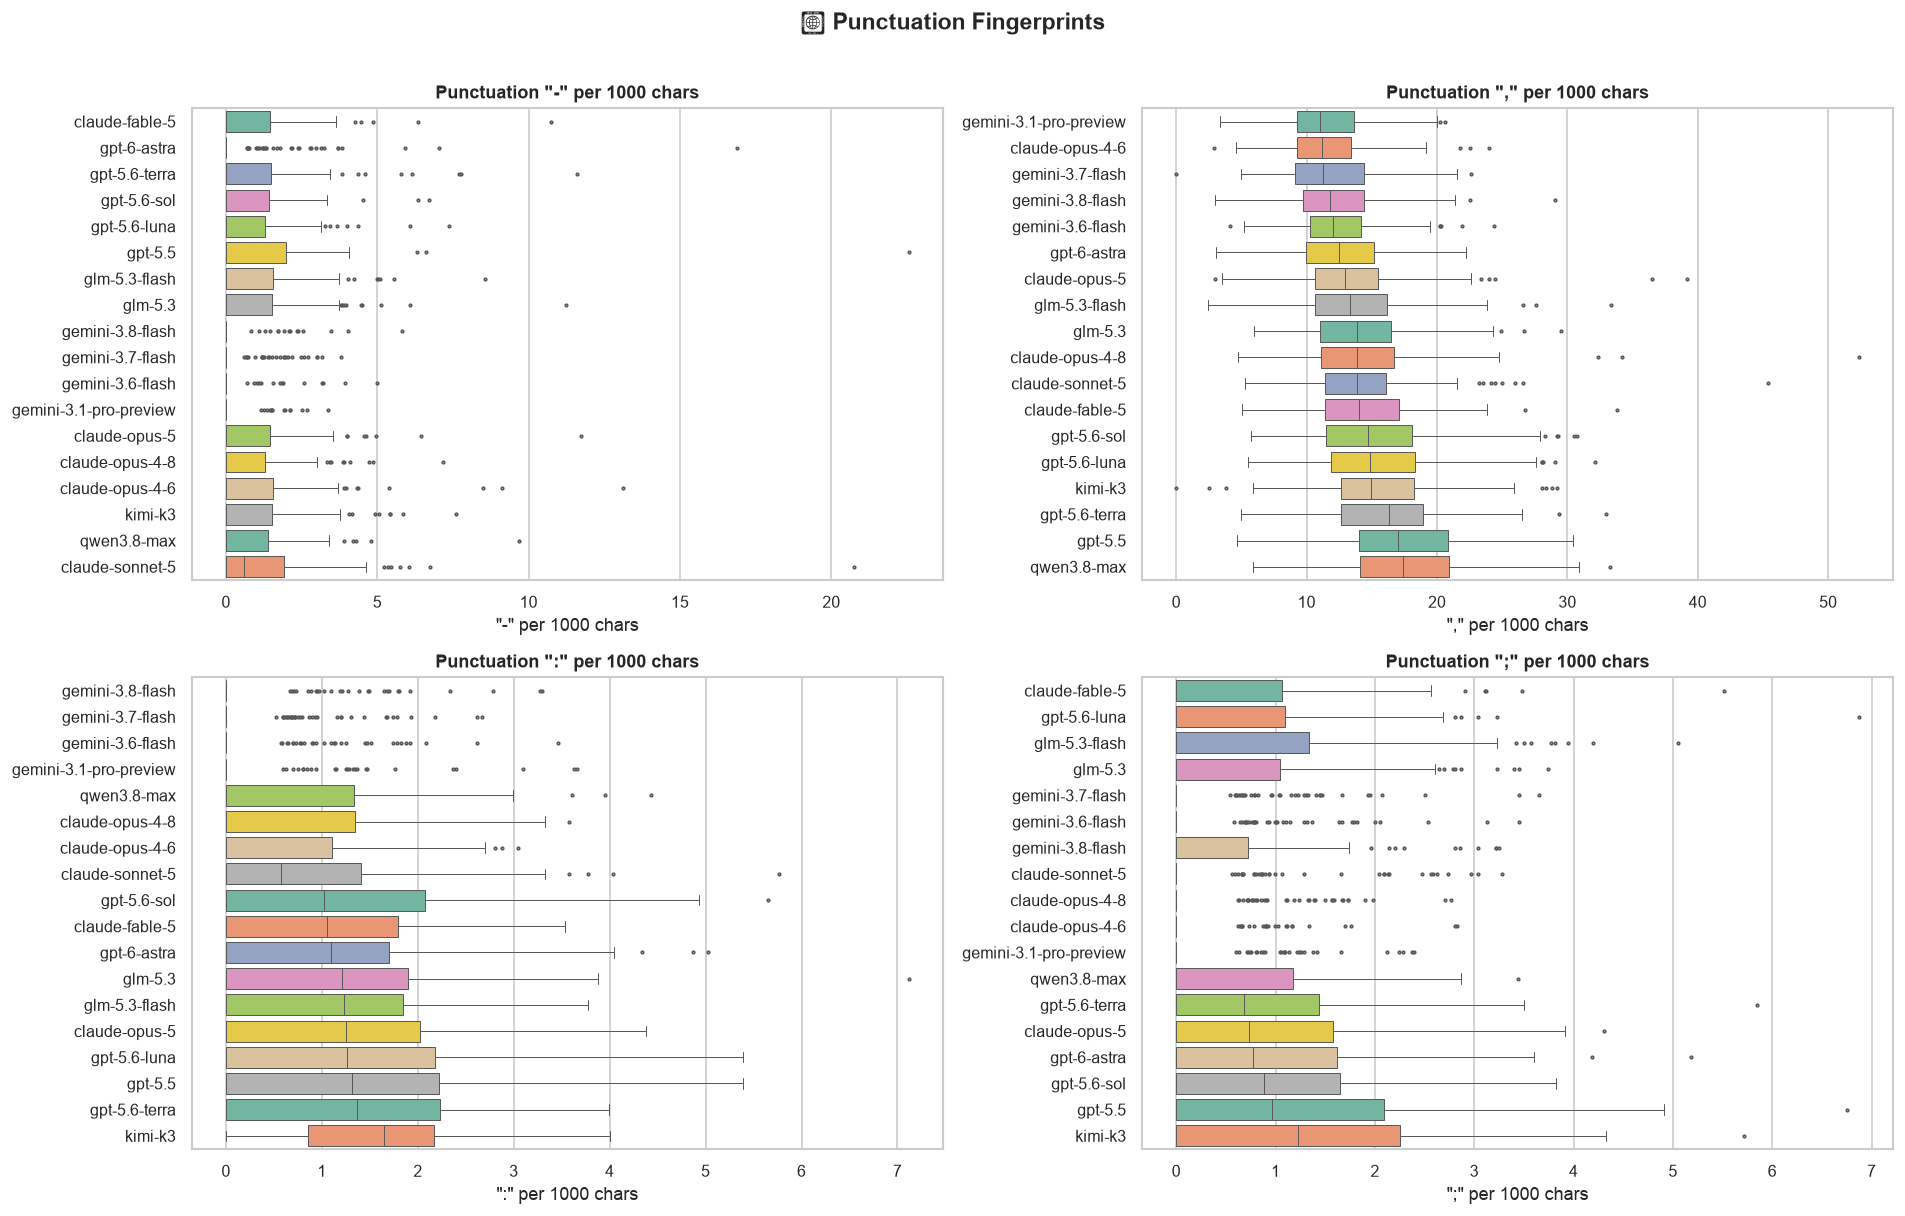

In [15]:
# key punctuation boxplots: dash, comma, colon, semicolon
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, p in zip(axes.flat, ['-', ',', ':', ';']):
    sns.boxplot(data=train, y='model', x=f'punct_{p}_norm',
                order=train.groupby('model')[f'punct_{p}_norm'].median().sort_values().index,
                palette='Set2', fliersize=1.5, linewidth=0.6, ax=ax)
    ax.set_title(f'Punctuation "{p}" per 1000 chars', fontweight='bold')
    ax.set_xlabel(f'"{p}" per 1000 chars')
    ax.set_ylabel('')
plt.suptitle('🔍 Punctuation Fingerprints', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## 5️⃣ Structural Patterns — Sentence Length, Vocabulary Richness

In [16]:
# ============================================================
# 5. Patterns: sentence structure, vocabulary richness, etc.
# ============================================================

def extract_features(text):
    """Extract stylistic features from a text passage."""
    words = text.split()
    n_words = len(words)
    n_chars = len(text)
    
    # sentence splitting (rough)
    sentences = re.split(r'[.!?]+', text)
    sentences = [s.strip() for s in sentences if s.strip()]
    n_sentences = max(len(sentences), 1)
    
    # average word length
    avg_word_len = np.mean([len(w.strip(string.punctuation)) for w in words]) if words else 0
    
    # average sentence length (in words)
    avg_sent_len = n_words / n_sentences
    
    # vocabulary richness (type-token ratio)
    unique_words = set(w.lower().strip(string.punctuation) for w in words)
    ttr = len(unique_words) / n_words if n_words > 0 else 0
    
    # hapax legomena ratio (words appearing exactly once)
    word_freq = Counter(w.lower().strip(string.punctuation) for w in words)
    hapax = sum(1 for w, c in word_freq.items() if c == 1)
    hapax_ratio = hapax / n_words if n_words > 0 else 0
    
    # long words ratio (>= 8 chars)
    long_words = sum(1 for w in words if len(w.strip(string.punctuation)) >= 8)
    long_word_ratio = long_words / n_words if n_words > 0 else 0
    
    # comma-to-sentence ratio
    n_commas = text.count(',')
    comma_per_sent = n_commas / n_sentences
    
    # em-dash usage (—, --, or isolated -)
    em_dashes = text.count('—') + text.count('--')
    
    # parenthetical usage
    parens = text.count('(') + text.count(')')
    
    # starts with certain patterns
    first_word = words[0].lower() if words else ''
    
    return {
        'n_words': n_words,
        'n_chars': n_chars,
        'n_sentences': n_sentences,
        'avg_word_len': avg_word_len,
        'avg_sent_len': avg_sent_len,
        'ttr': ttr,  # type-token ratio
        'hapax_ratio': hapax_ratio,
        'long_word_ratio': long_word_ratio,
        'comma_per_sent': comma_per_sent,
        'em_dashes': em_dashes,
        'parens': parens,
    }

# extract for all training data
feat_df = pd.DataFrame(train['text'].apply(extract_features).tolist())
train = pd.concat([train, feat_df], axis=1)

print('Extracted features:', list(feat_df.columns))
train[['model'] + list(feat_df.columns)].groupby('model').mean().round(2)

Extracted features: ['n_words', 'n_chars', 'n_sentences', 'avg_word_len', 'avg_sent_len', 'ttr', 'hapax_ratio', 'long_word_ratio', 'comma_per_sent', 'em_dashes', 'parens']


,n_words,n_chars,n_sentences,avg_word_len,avg_sent_len,ttr,hapax_ratio,long_word_ratio,comma_per_sent,em_dashes,parens
model,,,,,,,,,,,
claude-fable-5,112.50,731.02,4.74,5.43,23.96,0.82,0.72,0.22,2.28,1.50,0.15
claude-opus-4-6,115.15,771.21,4.33,5.67,26.99,0.82,0.72,0.26,2.13,1.30,0.00
claude-opus-4-8,123.59,809.81,5.11,5.50,23.72,0.80,0.71,0.23,2.27,0.97,0.03
claude-opus-5,123.44,762.81,5.23,5.11,23.58,0.78,0.69,0.18,2.07,1.50,0.04
claude-sonnet-5,120.05,816.58,4.59,5.74,26.04,0.83,0.73,0.25,2.60,1.26,0.01
gemini-3.1-pro-preview,119.35,782.97,5.78,5.50,20.22,0.80,0.72,0.25,1.53,0.00,0.00
gemini-3.6-flash,111.15,758.56,4.60,5.72,24.62,0.83,0.74,0.27,2.13,0.00,0.03
gemini-3.7-flash,117.11,828.69,4.81,5.95,23.84,0.84,0.76,0.29,1.91,0.01,0.01
gemini-3.8-flash,100.68,706.20,4.43,5.90,22.66,0.86,0.79,0.29,1.99,0.00,0.00


/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/2767017579.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, y='model', x=feat, order=order,
/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/2767017579.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, y='model', x=feat, order=order,
/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/2767017579.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, y='model', x=feat, order=order,
/var/folders/3z/l6z34vg53pb1zqh

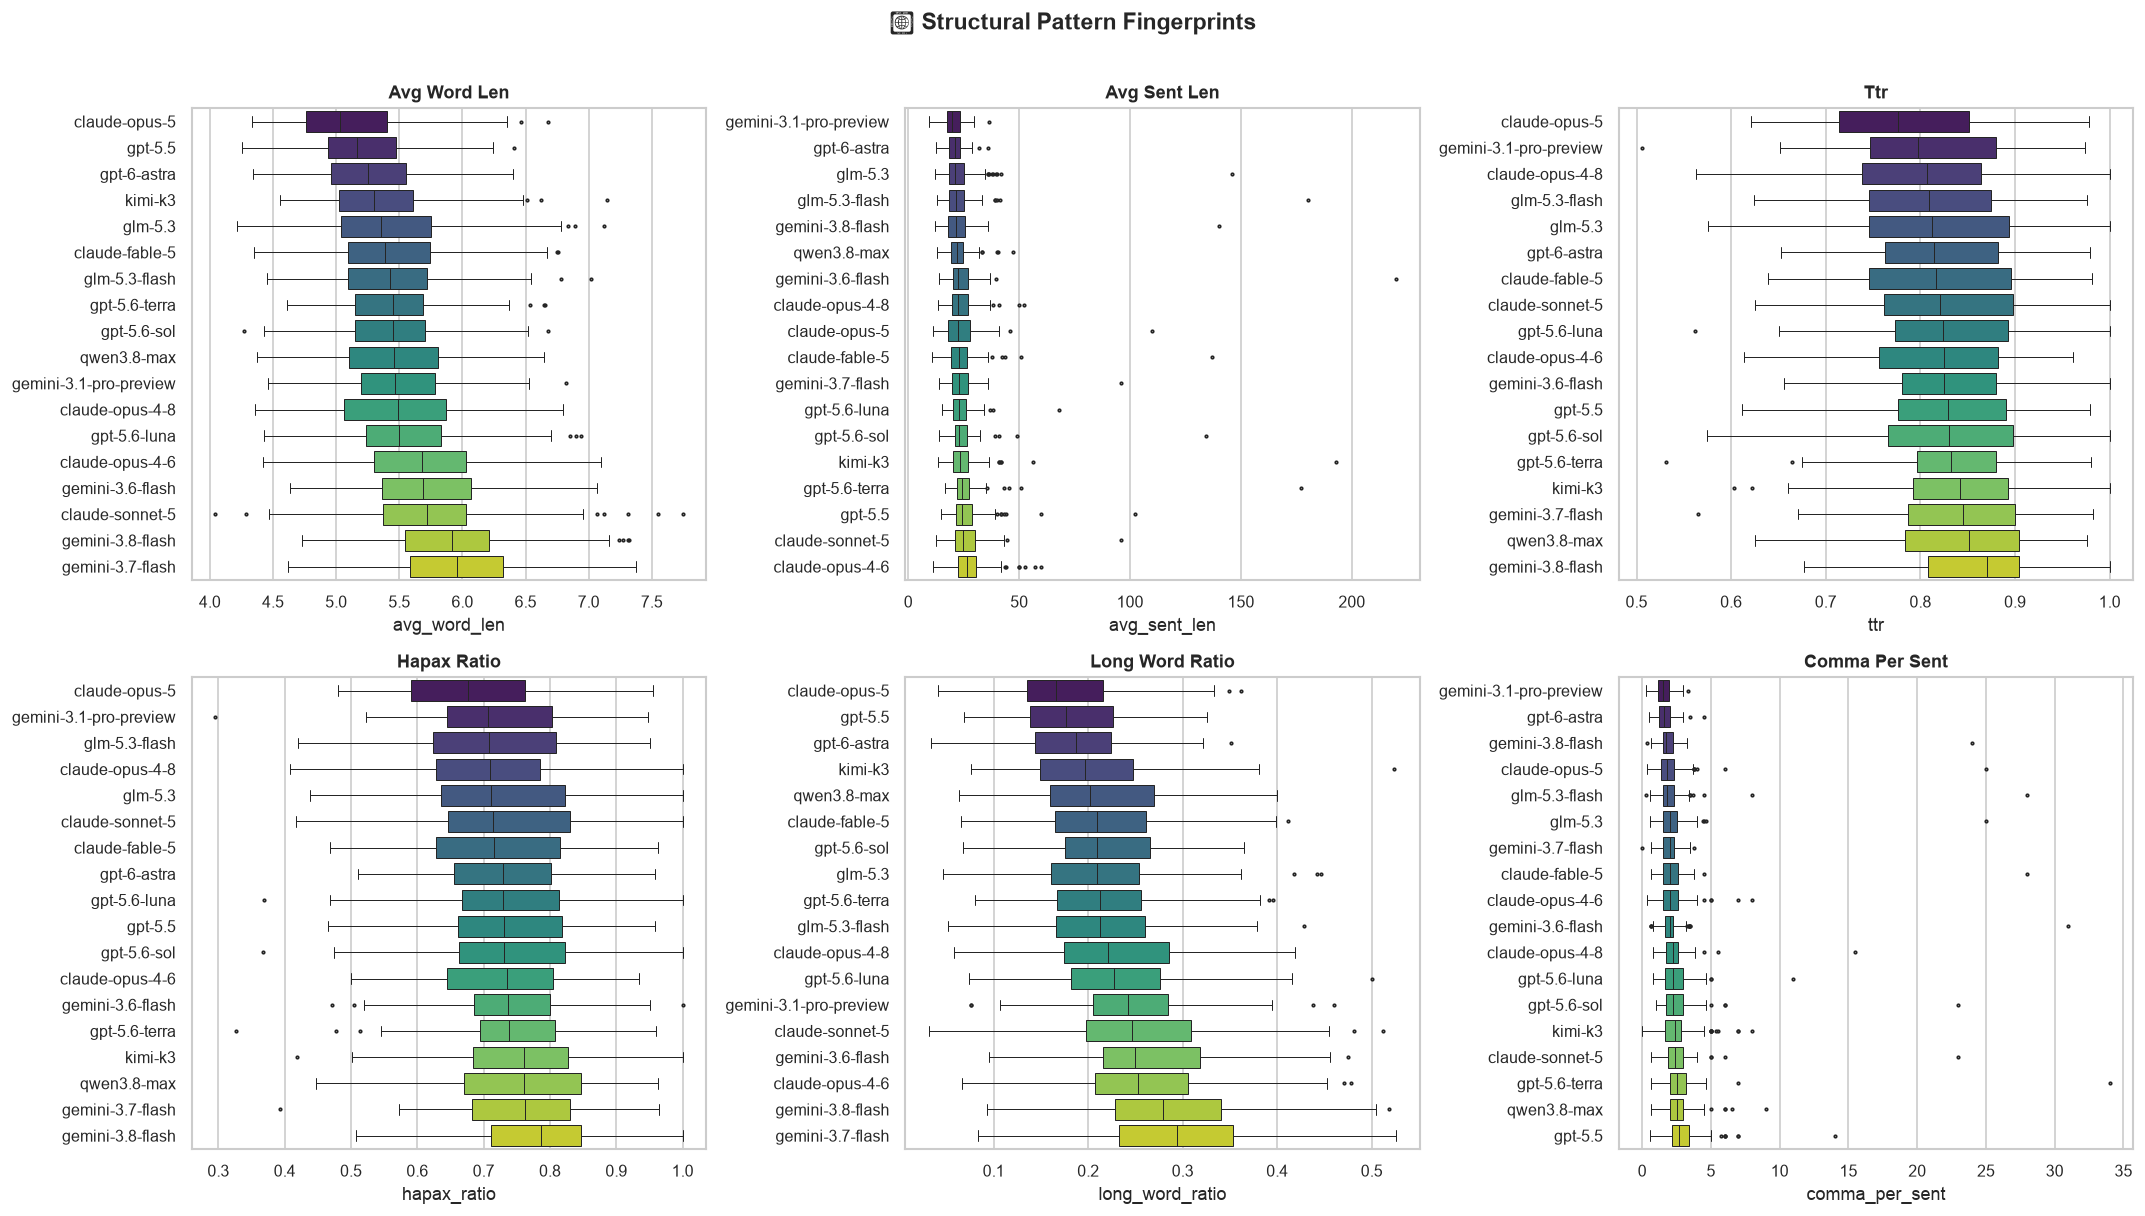

In [17]:
# pattern visualizations
pattern_features = ['avg_word_len', 'avg_sent_len', 'ttr', 'hapax_ratio',
                     'long_word_ratio', 'comma_per_sent']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, feat in zip(axes.flat, pattern_features):
    order = train.groupby('model')[feat].median().sort_values().index
    sns.boxplot(data=train, y='model', x=feat, order=order,
                palette='viridis', fliersize=1.5, linewidth=0.6, ax=ax)
    ax.set_title(feat.replace('_', ' ').title(), fontweight='bold')
    ax.set_ylabel('')
plt.suptitle('📐 Structural Pattern Fingerprints', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## 6️⃣ Family-Level vs Model-Level Characteristics

In [18]:
# ============================================================
# 6. Family → Model hierarchical analysis
# ============================================================

# family-level aggregation
family_features = ['text_len', 'word_count', 'avg_word_len', 'avg_sent_len',
                    'ttr', 'hapax_ratio', 'long_word_ratio', 'comma_per_sent']

family_stats = train.groupby('family')[family_features].mean().round(2)
print('📋 Family-level feature averages:\n')
print(family_stats.to_string())
print()

📋 Family-level feature averages:

             text_len  word_count  avg_word_len  avg_sent_len   ttr  hapax_ratio  long_word_ratio  comma_per_sent
family                                                                                                           
Anthropic      778.35      118.95          5.49         24.86  0.81         0.72             0.23            2.27
Google         769.10      112.07          5.77         22.84  0.83         0.75             0.27            1.89
Moonshot AI    690.13      107.37          5.36         25.54  0.84         0.75             0.20            2.51
OpenAI         748.29      115.13          5.39         24.23  0.83         0.74             0.21            2.48
Qwen           707.73      108.35          5.46         22.20  0.84         0.75             0.22            2.62
ZAI            743.94      114.75          5.43         23.08  0.81         0.72             0.21            2.14



/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/490004097.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, y='family', x=feat, order=family_order,
/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/490004097.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, y='family', x=feat, order=family_order,
/var/folders/3z/l6z34vg53pb1zqh53lwycs9h0000gn/T/ipykernel_25398/490004097.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, y='family', x=feat, order=family_order,
/var/fo

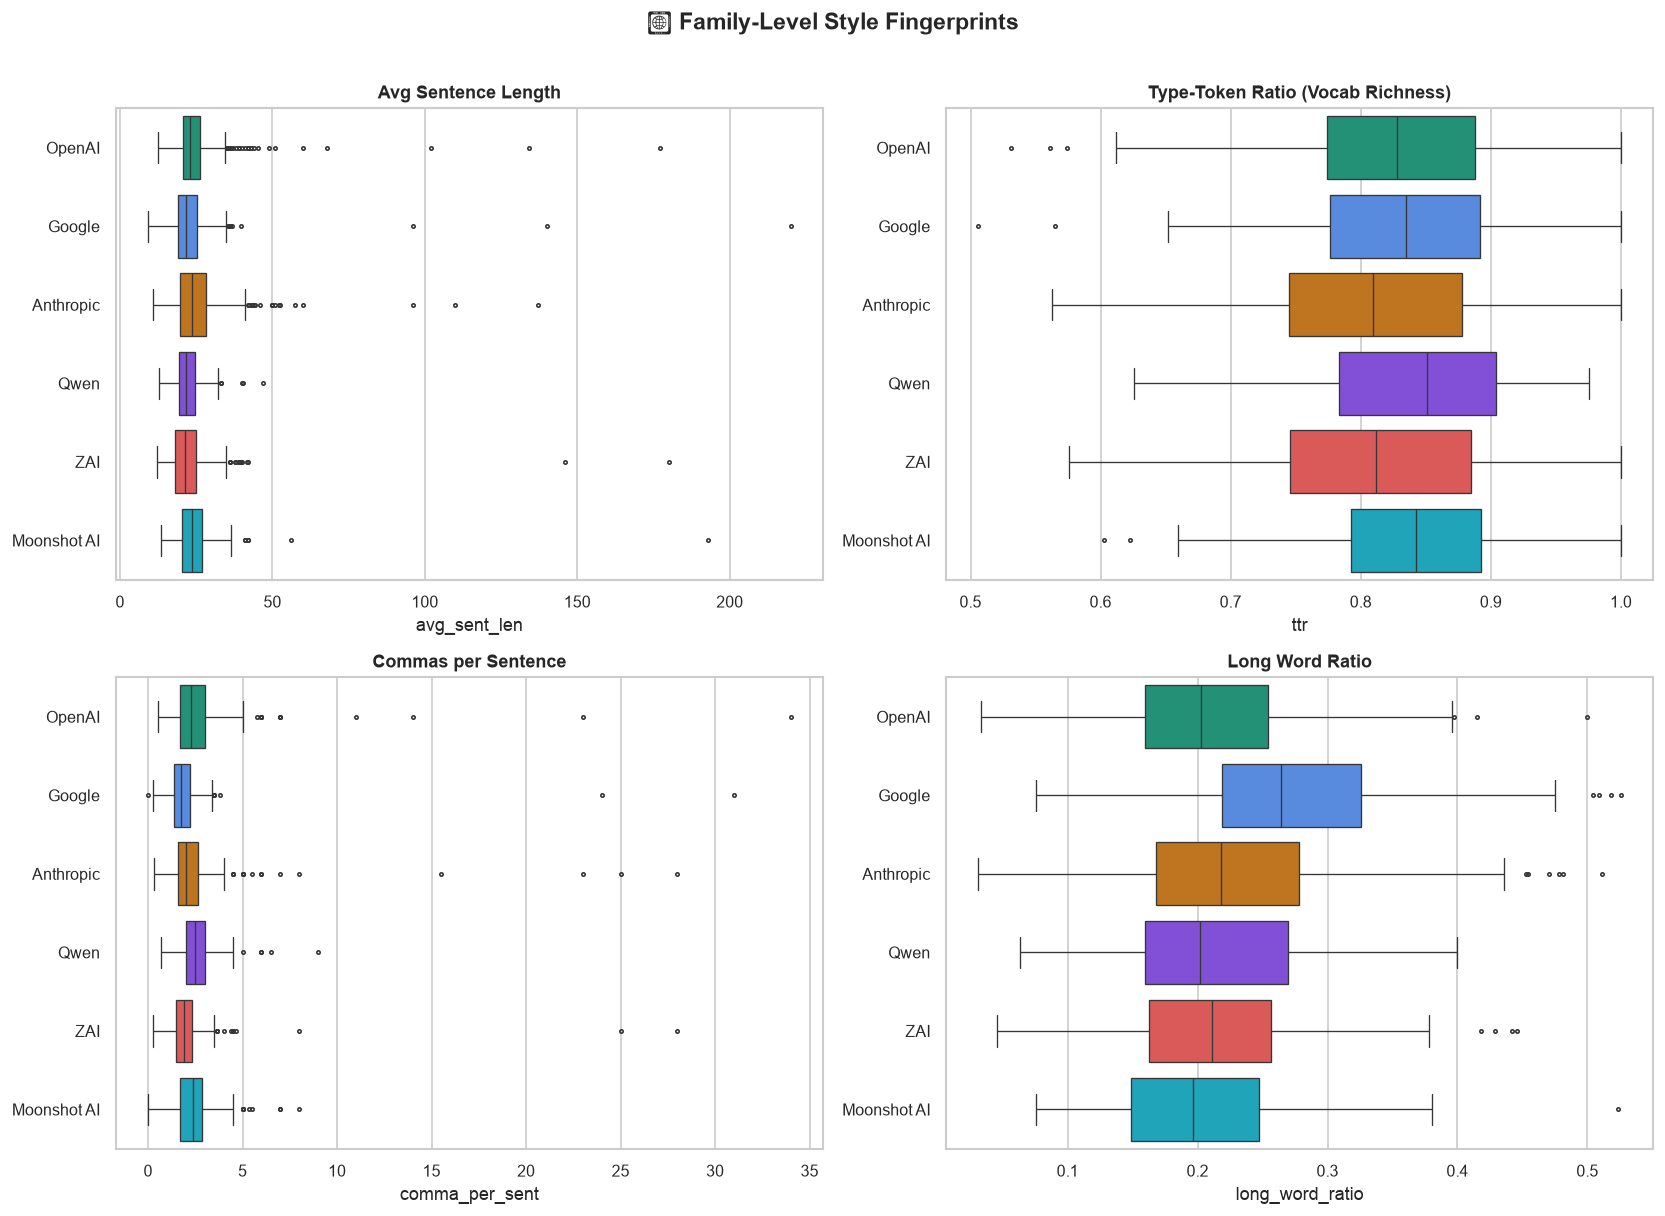

In [19]:
# family comparison plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

feats_to_plot = ['avg_sent_len', 'ttr', 'comma_per_sent', 'long_word_ratio']
titles = ['Avg Sentence Length', 'Type-Token Ratio (Vocab Richness)',
           'Commas per Sentence', 'Long Word Ratio']

family_order = ['OpenAI', 'Google', 'Anthropic', 'Qwen', 'ZAI', 'Moonshot AI']
family_palette = {'OpenAI': '#10a37f', 'Google': '#4285f4', 'Anthropic': '#d97706',
                   'Qwen': '#7c3aed', 'ZAI': '#ef4444', 'Moonshot AI': '#06b6d4'}

for ax, feat, title in zip(axes.flat, feats_to_plot, titles):
    sns.boxplot(data=train, y='family', x=feat, order=family_order,
                palette=family_palette, fliersize=2, linewidth=0.8, ax=ax)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('')

plt.suptitle('🏠 Family-Level Style Fingerprints', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [20]:
# within-family model discrimination
for family in family_order:
    sub = train[train['family'] == family]
    family_models = sub['model'].unique()
    if len(family_models) > 1:
        print(f'\n=== {family} ({len(family_models)} models) ===')
        stats = sub.groupby('model')[family_features].mean().round(2)
        print(stats.to_string())


=== OpenAI (5 models) ===
               text_len  word_count  avg_word_len  avg_sent_len   ttr  hapax_ratio  long_word_ratio  comma_per_sent
model                                                                                                              
gpt-5.5          698.65      110.27          5.21         26.03  0.83         0.74             0.18            2.91
gpt-5.6-luna     766.63      115.39          5.55         23.48  0.83         0.74             0.23            2.44
gpt-5.6-sol      779.35      118.93          5.46         24.53  0.83         0.74             0.21            2.54
gpt-5.6-terra    746.58      113.26          5.45         26.14  0.83         0.74             0.22            2.85
gpt-6-astra      750.25      117.77          5.27         20.98  0.82         0.73             0.19            1.66

=== Google (4 models) ===
                        text_len  word_count  avg_word_len  avg_sent_len   ttr  hapax_ratio  long_word_ratio  comma_per_sent
model    

---
## 🤖 Model Training — TF-IDF + Stylistic Features + Classifier

In [21]:
# ============================================================
# Feature Engineering for Classification
# ============================================================
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.base import BaseEstimator, TransformerMixin
from scipy.sparse import hstack, csr_matrix
import warnings
warnings.filterwarnings('ignore')

# ---------- custom transformer for handcrafted features ----------
class StyleFeatureExtractor(BaseEstimator, TransformerMixin):
    """Extract handcrafted stylistic features from text."""
    
    def __init__(self):
        self.punct_chars = ['-', ',', ':', ';', '!', '?', '(', ')', '"', "'"]
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        features = []
        for text in X:
            f = self._extract(text)
            features.append(f)
        return csr_matrix(np.array(features))
    
    def _extract(self, text):
        words = text.split()
        n_words = len(words)
        n_chars = len(text)
        
        sentences = re.split(r'[.!?]+', text)
        sentences = [s.strip() for s in sentences if s.strip()]
        n_sentences = max(len(sentences), 1)
        
        avg_word_len = np.mean([len(w.strip(string.punctuation)) for w in words]) if words else 0
        avg_sent_len = n_words / n_sentences
        
        unique_words = set(w.lower().strip(string.punctuation) for w in words)
        ttr = len(unique_words) / n_words if n_words > 0 else 0
        
        word_freq = Counter(w.lower().strip(string.punctuation) for w in words)
        hapax = sum(1 for w, c in word_freq.items() if c == 1)
        hapax_ratio = hapax / n_words if n_words > 0 else 0
        
        long_words = sum(1 for w in words if len(w.strip(string.punctuation)) >= 8)
        long_word_ratio = long_words / n_words if n_words > 0 else 0
        
        # punctuation features (normalized per 1000 chars)
        punct_feats = []
        for p in self.punct_chars:
            count = text.count(p)
            punct_feats.append(count / n_chars * 1000 if n_chars > 0 else 0)
        
        em_dashes = text.count('—') + text.count('--')
        n_commas = text.count(',')
        comma_per_sent = n_commas / n_sentences
        
        # additional patterns
        n_paragraphs = text.count('\n\n') + 1
        avg_para_len = n_words / n_paragraphs
        
        # proportion of sentences starting with certain words
        sent_starts = [s.split()[0].lower() if s.split() else '' for s in sentences]
        transition_words = {'however', 'moreover', 'furthermore', 'additionally',
                           'nevertheless', 'consequently', 'meanwhile', 'therefore',
                           'ultimately', 'indeed', 'thus', 'yet', 'still'}
        transition_ratio = sum(1 for w in sent_starts if w in transition_words) / n_sentences
        
        # digit ratio
        digit_ratio = sum(c.isdigit() for c in text) / n_chars if n_chars > 0 else 0
        
        # capital letter ratio (excluding sentence starts)
        cap_ratio = sum(1 for c in text if c.isupper()) / n_chars if n_chars > 0 else 0
        
        return [
            n_words, n_chars, n_sentences,
            avg_word_len, avg_sent_len, ttr, hapax_ratio,
            long_word_ratio, comma_per_sent, em_dashes,
            n_paragraphs, avg_para_len, transition_ratio,
            digit_ratio, cap_ratio,
        ] + punct_feats

print('StyleFeatureExtractor ready ✅')

StyleFeatureExtractor ready ✅


In [22]:
# ============================================================
# Build feature matrices
# ============================================================

# --- TF-IDF on words ---
tfidf_word = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=2,
    max_df=0.95,
    strip_accents='unicode'
)

# --- TF-IDF on characters ---
tfidf_char = TfidfVectorizer(
    analyzer='char_wb',
    max_features=10000,
    ngram_range=(3, 5),
    sublinear_tf=True,
    min_df=2,
    max_df=0.95,
)

# --- Stylistic features ---
style_extractor = StyleFeatureExtractor()

# fit and transform
X_train_text = train['text'].values
y_train = train['model'].values

X_tfidf_word = tfidf_word.fit_transform(X_train_text)
X_tfidf_char = tfidf_char.fit_transform(X_train_text)
X_style = style_extractor.fit_transform(X_train_text)

# combine all features
X_combined = hstack([X_tfidf_word, X_tfidf_char, X_style])

print(f'Word TF-IDF shape:  {X_tfidf_word.shape}')
print(f'Char TF-IDF shape:  {X_tfidf_char.shape}')
print(f'Style features:     {X_style.shape}')
print(f'Combined features:  {X_combined.shape}')
print(f'Labels:             {len(y_train)} samples, {len(set(y_train))} classes')

Word TF-IDF shape:  (2699, 15000)
Char TF-IDF shape:  (2699, 10000)
Style features:     (2699, 25)
Combined features:  (2699, 25025)
Labels:             2699 samples, 18 classes


In [23]:
# ============================================================
# Cross-validation with multiple classifiers
# ============================================================
from sklearn.metrics import classification_report, confusion_matrix

le = LabelEncoder()
y_encoded = le.fit_transform(y_train)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

classifiers = {
    'LogisticRegression': LogisticRegression(C=5.0, max_iter=2000, solver='saga', random_state=42),
    'LinearSVC': LinearSVC(C=1.0, max_iter=3000, random_state=42),
}

print('5-Fold Stratified Cross-Validation Results:\n')
results = {}
for name, clf in classifiers.items():
    scores = cross_val_score(clf, X_combined, y_encoded, cv=skf, scoring='accuracy', n_jobs=-1)
    results[name] = scores
    print(f'  {name:25s} → Mean: {scores.mean():.4f} ± {scores.std():.4f}  |  Folds: {np.round(scores, 4)}')

5-Fold Stratified Cross-Validation Results:

  LogisticRegression        → Mean: 0.1845 ± 0.0166  |  Folds: [0.1741 0.1574 0.1944 0.2037 0.1929]
  LinearSVC                 → Mean: 0.0745 ± 0.0217  |  Folds: [0.0704 0.1148 0.0556 0.0556 0.0761]


In [24]:
# ============================================================
# Train best model on full training data & generate predictions
# ============================================================

# pick the best classifier based on CV
best_name = max(results, key=lambda k: results[k].mean())
print(f'Best classifier: {best_name} (CV accuracy: {results[best_name].mean():.4f})\n')

# retrain on full training data
best_clf = classifiers[best_name]
best_clf.fit(X_combined, y_encoded)

# --- detailed classification report via CV predictions ---
from sklearn.model_selection import cross_val_predict
y_cv_pred = cross_val_predict(classifiers[best_name], X_combined, y_encoded, cv=skf)
print('\nClassification Report (CV predictions):\n')
print(classification_report(y_encoded, y_cv_pred, target_names=le.classes_))

Best classifier: LogisticRegression (CV accuracy: 0.1845)


Classification Report (CV predictions):

                        precision    recall  f1-score   support

        claude-fable-5       0.50      0.01      0.01       149
       claude-opus-4-6       0.19      0.21      0.20       150
       claude-opus-4-8       0.15      0.03      0.05       150
         claude-opus-5       0.21      0.41      0.28       150
       claude-sonnet-5       0.24      0.34      0.28       150
gemini-3.1-pro-preview       0.29      0.34      0.31       150
      gemini-3.6-flash       0.14      0.07      0.09       150
      gemini-3.7-flash       0.22      0.37      0.28       150
      gemini-3.8-flash       0.17      0.27      0.20       150
               glm-5.3       0.20      0.07      0.10       150
         glm-5.3-flash       0.29      0.15      0.20       150
               gpt-5.5       0.14      0.29      0.19       150
          gpt-5.6-luna       0.07      0.03      0.04       150
  

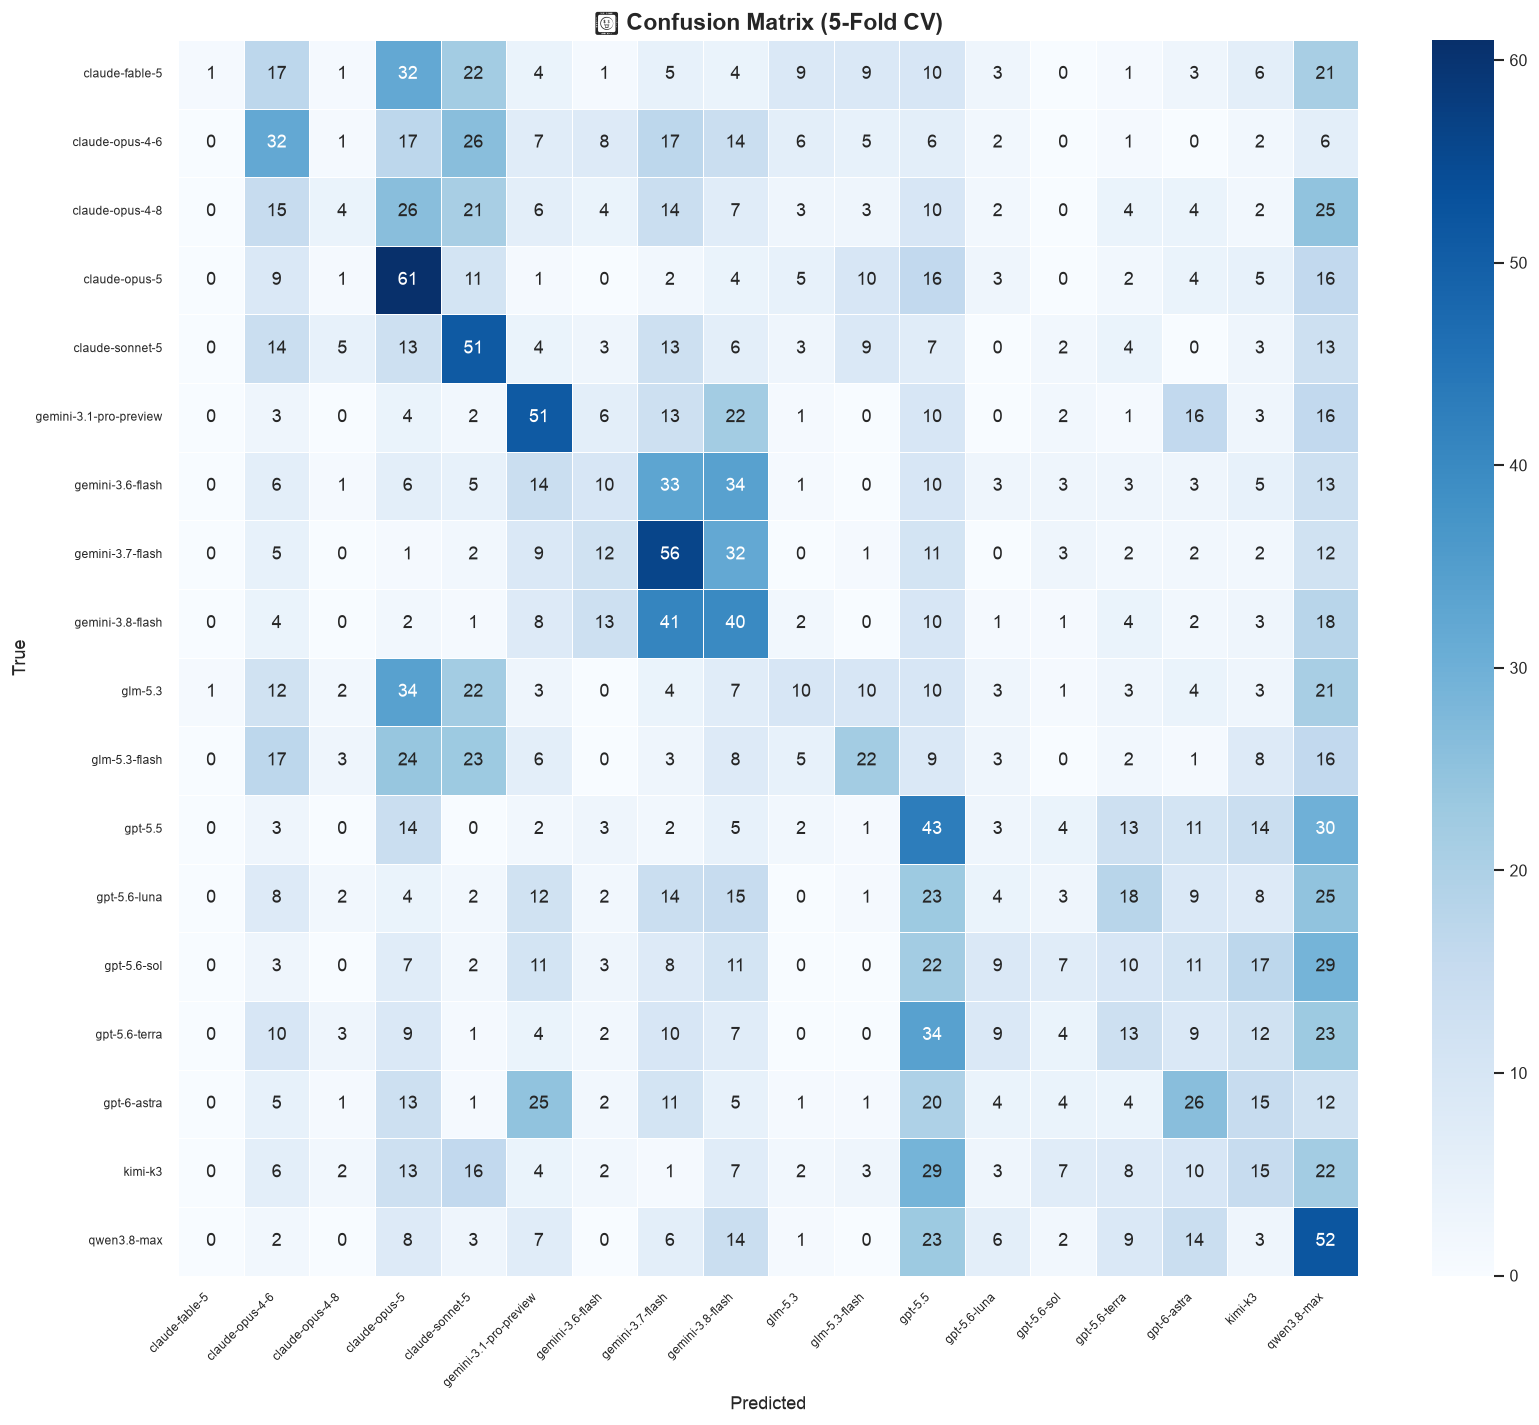

In [25]:
# confusion matrix
cm = confusion_matrix(y_encoded, y_cv_pred)
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_,
            linewidths=0.3, ax=ax)
ax.set_title('🧩 Confusion Matrix (5-Fold CV)', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
plt.xticks(rotation=45, ha='right', fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

---
## 📤 Generate Submission

In [26]:
# ============================================================
# Generate submission.parquet
# ============================================================

# retrain final model on ALL training data
final_clf = LogisticRegression(C=5.0, max_iter=2000, solver='saga', random_state=42)
final_clf.fit(X_combined, y_encoded)

# transform test data
X_test_text = test['text'].values
X_test_tfidf_word = tfidf_word.transform(X_test_text)
X_test_tfidf_char = tfidf_char.transform(X_test_text)
X_test_style = style_extractor.transform(X_test_text)
X_test_combined = hstack([X_test_tfidf_word, X_test_tfidf_char, X_test_style])

# predict
y_test_pred = final_clf.predict(X_test_combined)
predictions = le.inverse_transform(y_test_pred)

# validate
assert all(p in VALID_LABELS for p in predictions), 'Invalid label in predictions!'

# create submission
submission = pd.DataFrame({'id': test['id'], 'model': predictions})
assert submission['id'].nunique() == len(submission), 'Duplicate IDs!'
assert submission['model'].notna().all(), 'Null predictions!'

submission.to_parquet('submission.parquet', index=False)

print(f'✅ Submission saved: submission.parquet')
print(f'   Rows: {len(submission)}')
print(f'   Unique models predicted: {submission["model"].nunique()}')
print(f'\nPrediction distribution:')
print(submission['model'].value_counts().to_string())
print(f'\nFirst few rows:')
submission.head(10)

✅ Submission saved: submission.parquet
   Rows: 3
   Unique models predicted: 3

Prediction distribution:
model
gpt-5.6-terra       1
gemini-3.6-flash    1
gemini-3.7-flash    1

First few rows:


,id,model
0,00353fb1c541,gpt-5.6-terra
1,005f5a9a6139,gemini-3.6-flash
2,0062a53d5487,gemini-3.7-flash


In [27]:
# quick sanity check — read back
check = pd.read_parquet('submission.parquet')
print(f'Readback shape: {check.shape}')
print(f'Columns: {list(check.columns)}')
print(f'Any nulls: {check.isnull().any().any()}')
print(f'All labels valid: {all(m in VALID_LABELS for m in check["model"])}')
check.head()

Readback shape: (3, 2)
Columns: ['id', 'model']
Any nulls: False
All labels valid: True


,id,model
0,00353fb1c541,gpt-5.6-terra
1,005f5a9a6139,gemini-3.6-flash
2,0062a53d5487,gemini-3.7-flash
